## Introduction to Quantum Computing: Labs

### Solution for Lab 5: Multi-Qubit Gates and Single-Qubit Measurements

In the lecture, we learned that single-qubit gates alone are not sufficient to implement complex quantum algorithms. To solve interesting problems, we need gates that entangle two or more qubits or make their states depend on each other.

We will start with the most important two-qubit gate: the **CX gate** (also called the CNOT gate).

In this notebook, we will explore how these gates work and how to use them in Qiskit. A CX gate is added in Qiskit as follows:

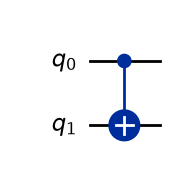

In [21]:
import numpy as np
from qiskit import QuantumCircuit
from qc_lecture_tools.statevector import sv_state

# Example of a CX gate
qc_example = QuantumCircuit(2)
qc_example.cx(0, 1) # Two indices for the qubits
qc_example.draw("mpl")

### Exercise 1: Getting to Know the CX Gate

**Exercise 1.1:** Create a quantum circuit with 2 qubits and add a CX gate. Experiment with the order of the indices (e.g. `qc.cx(0, 1)` vs. `qc.cx(1, 0)`). Draw the circuit. What do you notice about how the gates are displayed?

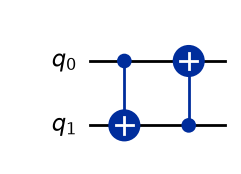

In [22]:
quantum_circuit = QuantumCircuit(2)
quantum_circuit.cx(0, 1)
quantum_circuit.cx(1, 0) 
quantum_circuit.draw("mpl")

**Observation:** There is a clear difference between the first and the second qubit. The first qubit is marked with a small circle (indicating the control qubit), and the second qubit is marked with a large circle (where the X gate is applied).

**Exercise 1.2:** Analyze the logical function of the CX gate.
Prepare each of the four basis states $\ket{00}$, $\ket{01}$, $\ket{10}$, and $\ket{11}$ in turn using $X$ gates, and apply the CX gate to each one.

Examine the result using `sv_state(quantum_circuit)`. What happens to the target qubit depending on the control qubit?

In [23]:
quantum_circuit = QuantumCircuit(2)
quantum_circuit.cx(0, 1)
display(sv_state(quantum_circuit, "Application to the 00 state:"))

quantum_circuit = QuantumCircuit(2)
quantum_circuit.x(0)
quantum_circuit.cx(0, 1)
display(sv_state(quantum_circuit, "Application to the 10 state:"))

quantum_circuit = QuantumCircuit(2)
quantum_circuit.x(1)
quantum_circuit.cx(0, 1)
display(sv_state(quantum_circuit, "Application to the 01 state:"))

quantum_circuit = QuantumCircuit(2)
quantum_circuit.x(0)
quantum_circuit.x(1)
quantum_circuit.cx(0, 1)
display(sv_state(quantum_circuit, "Application to the 11 state:"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Observation:** The first qubit controls whether the X gate is applied. If the first qubit is in the 1 state, the X gate is applied; otherwise, it is not.

**Exercise 1.3:** Bell states are maximally entangled states. Work out how the following state can be prepared using a Hadamard gate and a CX gate:
$$\ket{\Psi} = \frac{\sqrt{2}}{2}\ket{00} + \frac{\sqrt{2}}{2}\ket{11}$$

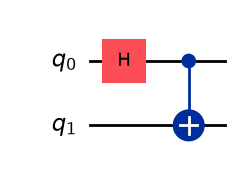

<IPython.core.display.Math object>

In [24]:
quantum_circuit = QuantumCircuit(2)
quantum_circuit.h(0)
quantum_circuit.cx(0, 1)
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit))

**Exercise 1.4:** We now extend the system to three qubits. Which circuit can be used to prepare the so-called GHZ state?
$$\ket{\Psi} = \frac{\sqrt{2}}{2}\ket{000} + \frac{\sqrt{2}}{2}\ket{111}$$

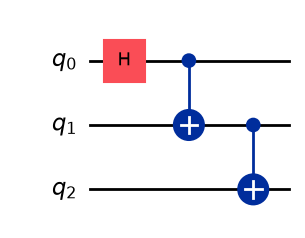

<IPython.core.display.Math object>

In [25]:
quantum_circuit = QuantumCircuit(3)
quantum_circuit.h(0)
quantum_circuit.cx(0, 1)
quantum_circuit.cx(1, 2)
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit))

**Exercise 1.5:** Find a circuit that prepares the following entangled state:
$$\ket{\Psi} = 
\frac{\sqrt{2}}{2} \ket{01} + \frac{\sqrt{2}}{2}\ket{10}$$

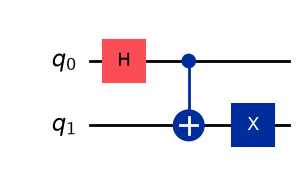

<IPython.core.display.Math object>

In [26]:
quantum_circuit = QuantumCircuit(2)
quantum_circuit.h(0)
quantum_circuit.cx(0, 1)
quantum_circuit.x(1)
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit))

### Exercise 2: Other Controlled Gates and the SWAP Gate

In addition to the CX gate (controlled NOT), almost all single-qubit gates can be converted into a controlled form.

**Exercise 2.1:** Work out (or look up in the Qiskit documentation) how to create the controlled versions of the $H$, $Y$, $Z$, and $S$ gates.

Try applying these gates to the superposition state
$$\ket{\Psi} = \frac12 \ket{00} + \frac12 \ket{01} + \frac12 \ket{10} + \frac12 \ket{11}$$
and observe the change in the state vector using `sv_state`.

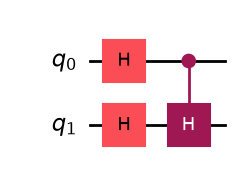

<IPython.core.display.Math object>

In [27]:
quantum_circuit = QuantumCircuit(2)
quantum_circuit.h([0,1])
quantum_circuit.ch(0,1)
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit, "Controlled H gate:"))

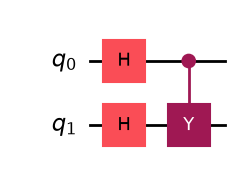

<IPython.core.display.Math object>

In [28]:
quantum_circuit = QuantumCircuit(2)
quantum_circuit.h([0,1])
quantum_circuit.cy(0,1)
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit))

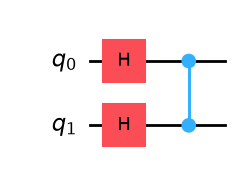

<IPython.core.display.Math object>

In [29]:
quantum_circuit = QuantumCircuit(2)
quantum_circuit.h([0,1])
quantum_circuit.cz(0,1)
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit))

Another useful gate is the **SWAP gate**, which exchanges the states of two qubits.

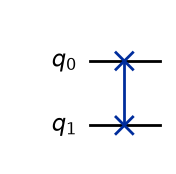

In [30]:
qc_swap = QuantumCircuit(2)
qc_swap.swap(0, 1)
qc_swap.draw("mpl")

**Exercise 2.2:** Create a circuit with two qubits. Put qubit 0 into superposition using a Hadamard gate, while qubit 1 remains in the $\ket{0}$ state. Then apply the SWAP gate.

Examine the result using `sv_state`. What does the SWAP gate do?

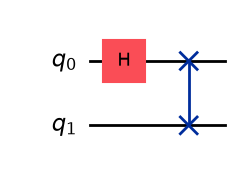

<IPython.core.display.Math object>

In [31]:
quantum_circuit = QuantumCircuit(2)
quantum_circuit.h(0)
quantum_circuit.swap(0,1)
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit))

**Observation:** The 1 and the 0 are swapped.

**Exercise 2.3:** The SWAP gate can also be implemented using only CNOT gates (CX).

Find a combination of CX gates that has the same effect as a SWAP gate. Test your solution on the states $\ket{00}, \ket{01}$, $\ket{10}$, and $\ket{11}$.

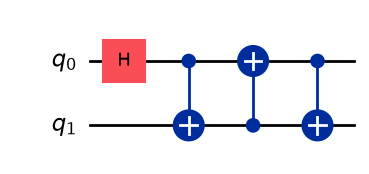

<IPython.core.display.Math object>

In [32]:
quantum_circuit = QuantumCircuit(2)
quantum_circuit.h(0)

# Implementation of a SWAP gate using three CX gates
quantum_circuit.cx(0, 1)
quantum_circuit.cx(1, 0)
quantum_circuit.cx(0, 1)
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit))

### Exercise 3: Gates with Multiple Control Qubits

There are also gates that are applied only when several control qubits are in the $\ket{1}$ state at the same time. A well-known example is the **Toffoli gate** (CCX).

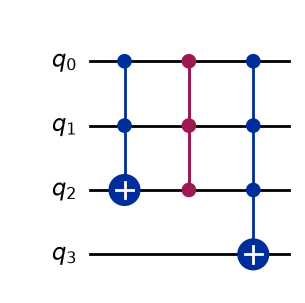

In [33]:
qc_multi = QuantumCircuit(4)

# Toffoli gate (CCX): Qubits 0 & 1 are control qubits, 2 is the target qubit
qc_multi.ccx(0, 1, 2)  

# Doubly controlled Z gate (CCZ)
qc_multi.ccz(0, 1, 2) 

# Multi-controlled NOT (MCX): Any number of control qubits
qc_multi.mcx([0, 1, 2], 3) 

qc_multi.draw("mpl")

**Exercise 3.1:** Create a superposition over the first two qubits of a 3-qubit system. Then apply the Toffoli gate (CCX). Examine the quantum state using `sv_state`. What do you observe?

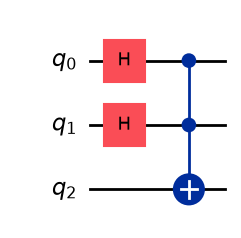

<IPython.core.display.Math object>

In [34]:
quantum_circuit = QuantumCircuit(3)
quantum_circuit.h([0,1])
quantum_circuit.ccx(0, 1, 2)
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit, "State after the Toffoli gate:"))

**Exercise 3.2:** Create a circuit with three qubits, all of which are put into superposition using Hadamard gates. Then apply the **CCZ gate** to all three qubits.

Examine the state vector using `sv_state`. Which component of the state changes? Why does the order of the qubits not matter for the CCZ gate (unlike the CCX gate)?

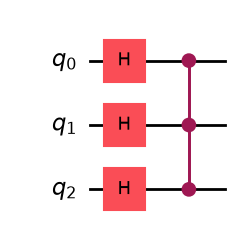

<IPython.core.display.Math object>

In [35]:
quantum_circuit = QuantumCircuit(3)
quantum_circuit.h([0,1,2])
quantum_circuit.ccz(0, 1, 2)
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit, "State after the CCZ gate:"))

**Exercise 3.3:** By default, controlled gates respond to the $\ket{1}$ state. Work out how to build a circuit in which an X gate is applied to qubit 2 only when qubit 0 and qubit 1 are in the $\ket{0}$ state.

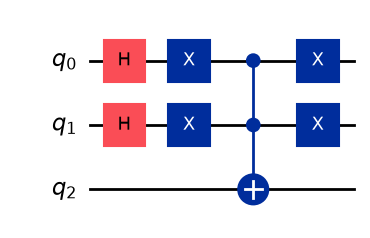

<IPython.core.display.Math object>

In [36]:
quantum_circuit = QuantumCircuit(3)
quantum_circuit.h([0,1])
quantum_circuit.x([0,1])
quantum_circuit.ccx(0, 1,2)
quantum_circuit.x([0,1])
display(quantum_circuit.draw("mpl"))
display(sv_state(quantum_circuit, "State after the CCZ gate:"))


### Exercise 4: Measuring a Single Qubit

Finally, we will investigate what happens when we measure a single qubit in a system of several qubits.

What happens to qubit 1 if we measure **only qubit 0**? Does qubit 1 then also have to be in a basis state?

We will use the familiar helper function `sample_from_circuit`. It can also execute circuits in which only one qubit is measured or further gates are applied after a measurement. Each shot starts with a fresh preparation of the initial state.

**Minimal example with one qubit:** We prepare a superposition and measure qubit 0 into classical bit 0. With 1000 shots, we expect the outcomes `0` and `1` to occur roughly half the time each.


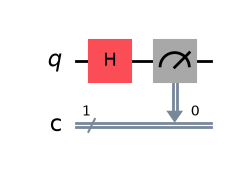

{'1': 512, '0': 488}

In [37]:
from qc_lecture_tools.sampling import sample_from_circuit

qc_beispiel = QuantumCircuit(1, 1)  # One qubit and one classical bit
qc_beispiel.h(0)
qc_beispiel.measure(0, 0)  # Measure qubit 0 and store the result in classical bit 0
display(qc_beispiel.draw("mpl"))
sample_from_circuit(qc_beispiel, num_shots=1000)

**Exercise 4.1:** Use Hadamard gates to put both qubits into the state
$$\ket{\Psi}=\frac12\ket{00}+\frac12\ket{01}+\frac12\ket{10}+\frac12\ket{11}.$$

Examine the state using `sv_state`. Which measurement outcomes do you expect for qubit 0, and with which probabilities? What do you expect for qubit 1 afterwards?

Then measure **only qubit 0** and run 1000 shots using `sample_from_circuit`. Why do the results contain only one bit?

For each of the two measurement outcomes, write down the joint state afterwards. Which qubit has a definite value, and which remains in superposition?


<IPython.core.display.Math object>

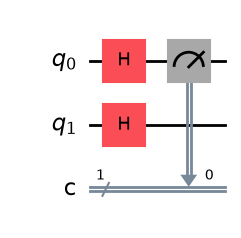

{'0': 518, '1': 482}

In [38]:
qc_superposition = QuantumCircuit(2, 1)
qc_superposition.h([0, 1])
display(sv_state(qc_superposition))

qc_messung = qc_superposition.copy()
qc_messung.measure(0, 0)
display(qc_messung.draw("mpl"))
sample_from_circuit(qc_messung, num_shots=1000)


**Observation:** The classical bit contains only the result for qubit 0; qubit 1 was not measured. Both outcomes have probability $\frac12$. Afterwards:
$$\begin{aligned}
q_0=0:\quad &\frac{1}{\sqrt{2}}\ket{00}+\frac{1}{\sqrt{2}}\ket{01}
=\ket{0}\otimes\ket{+},\\
q_0=1:\quad &\frac{1}{\sqrt{2}}\ket{10}+\frac{1}{\sqrt{2}}\ket{11}
=\ket{1}\otimes\ket{+}.
\end{aligned}$$
With $\ket{+}=(\ket{0}+\ket{1})/\sqrt{2}$, qubit 1 therefore remains in superposition.


**Exercise 4.2:** Check the remaining superposition: First measure only qubit 0. **Afterwards**, apply a Hadamard gate to qubit 1, and only then measure qubit 1 as well.

Use two classical bits and 1000 shots. Which value does qubit 1 always return? Explain this using $H\ket{+}=\ket{0}$.

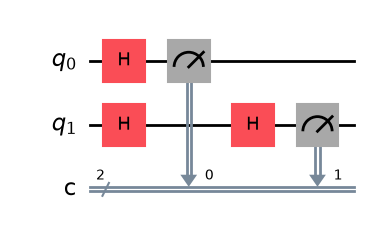

{'10': 498, '00': 502}

In [39]:
qc_test = QuantumCircuit(2, 2)
qc_test.h([0, 1])
qc_test.measure(0, 0)
qc_test.h(1)
qc_test.measure(1, 1)
display(qc_test.draw("mpl"))
sample_from_circuit(qc_test, num_shots=1000)


**Observation:** Only `00` and `10` occur: after $H$, qubit 1 always returns 0. Its superposition was preserved after the first measurement and allows interference. A randomly prepared basis state, on the other hand, would yield both outcomes with equal probability after $H$.


**Exercise 4.3:** Repeat the experiment for the Bell state from Exercise 1.3:
$$\ket{\Phi^+}=\frac{1}{\sqrt{2}}\ket{00}+\frac{1}{\sqrt{2}}\ket{11}.$$

Measure qubit 0 first. Compare the subsequent measurement of qubit 1 **without** and **with** a Hadamard gate applied beforehand. Is qubit 1 still in superposition immediately after the measurement of qubit 0?

Evaluate the statement: "Measuring one qubit always fixes the entire two-qubit state to a basis state."


In [40]:
qc_bell = QuantumCircuit(2, 2)
qc_bell.h(0)
qc_bell.cx(0, 1)
qc_bell.measure(0, 0)

qc_bell_ohne_h = qc_bell.copy()
qc_bell_ohne_h.measure(1, 1)
display(sample_from_circuit(qc_bell_ohne_h, num_shots=1000))

qc_bell.h(1)
qc_bell.measure(1, 1)
display(sample_from_circuit(qc_bell, num_shots=1000))


{'00': 497, '11': 503}

{'10': 235, '01': 258, '00': 250, '11': 257}

**Observation:** For the Bell state, the state after the first measurement is either $\ket{00}$ or $\ket{11}$, depending on the outcome. Without $H$, only `00` and `11` therefore occur. Applying $H$ creates a superposition on qubit 1 again; all four outcomes then occur with a probability of approximately $\frac14$ each.

The statement is **false**: Whether the unmeasured qubit remains in superposition depends on the joint initial state. Measuring one qubit therefore does not have to destroy every superposition in the system.
